# The TSMC fab and Kumamoto land prices: what we found

**For:** planners, landowners, developers and investors following the semiconductor build-out around Kikuyo, Kumamoto.
**Data:** MLIT benchmark land prices (地価公示) for Kumamoto Prefecture, 2013–2026: about 250 official plots valued every January 1.
**Event:** TSMC confirmed its Kumamoto fab (JASM) in October 2021, so the January 2022 valuation is the first after it.

## Summary

1. **The fab created a land-price premium, and it is local.** Since the announcement, land within 5 km of the fab has grown about **7 percentage points a year faster** than it otherwise would have. At 5–10 km the gain is about 2 points a year. **Beyond 10 km there is no measurable effect.**
2. **In money terms,** typical residential land within 5 km went from about ¥50,600 to ¥72,200 per m² between 2021 and 2026 (**+42%**). The prefecture-wide median was +10%.
3. **The towns that gained most** were Kikuyo (+46%), Ozu (+44%) and Koshi (+36%).
4. **The boom is cooling.** Growth within 5 km roughly halved in the 2026 valuation, from 14.1% to 7.6%.
5. **The growth zone is mostly outside mapped flood areas:** 16 of 17 plots within 5 km.
6. **What this project cannot do yet is forecast.** No model predicted the 2025–2026 changes better than the rule "same as last year". Its value today is *measuring* the fab's impact and *monitoring* it each year, not predicting prices.

The last section sets out the work that would turn this into a decision-grade monitoring tool.

<details><summary>How to re-run this notebook</summary>

Run `python scripts/download_data.py` and `python main.py --all` from the repository root first. This notebook only reads the pipeline's outputs in `data/analysis/` and `docs/figures/`.
</details>

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from matplotlib.patches import Patch
from src import config, fab_impact, plot_style, train
%matplotlib inline

panel = pd.read_csv(fab_impact.PANEL_PATH, encoding="utf-8-sig")
cum = pd.read_csv(fab_impact.CUMULATIVE_PATH, encoding="utf-8-sig")
bands = pd.read_csv(fab_impact.DISTANCE_BANDS_PATH, encoding="utf-8-sig")
did = json.load(open(fab_impact.DID_RESULTS_PATH, encoding="utf-8"))
comparison = pd.read_csv(config.MODEL_COMPARISON_PATH)
s2 = pd.read_csv(config.STAGE2_PATH, encoding="utf-8-sig")
rings = pd.DataFrame(did["rings"])

## 1. Land near the fab took off after the announcement

Each line is the average yearly price change of the benchmark plots at a given distance from the fab. Before 2022 every distance band moved within a few points of the others. From 2023 the plots within 5 km pulled away, rising 10–14% a year, while the rest of the prefecture barely moved.

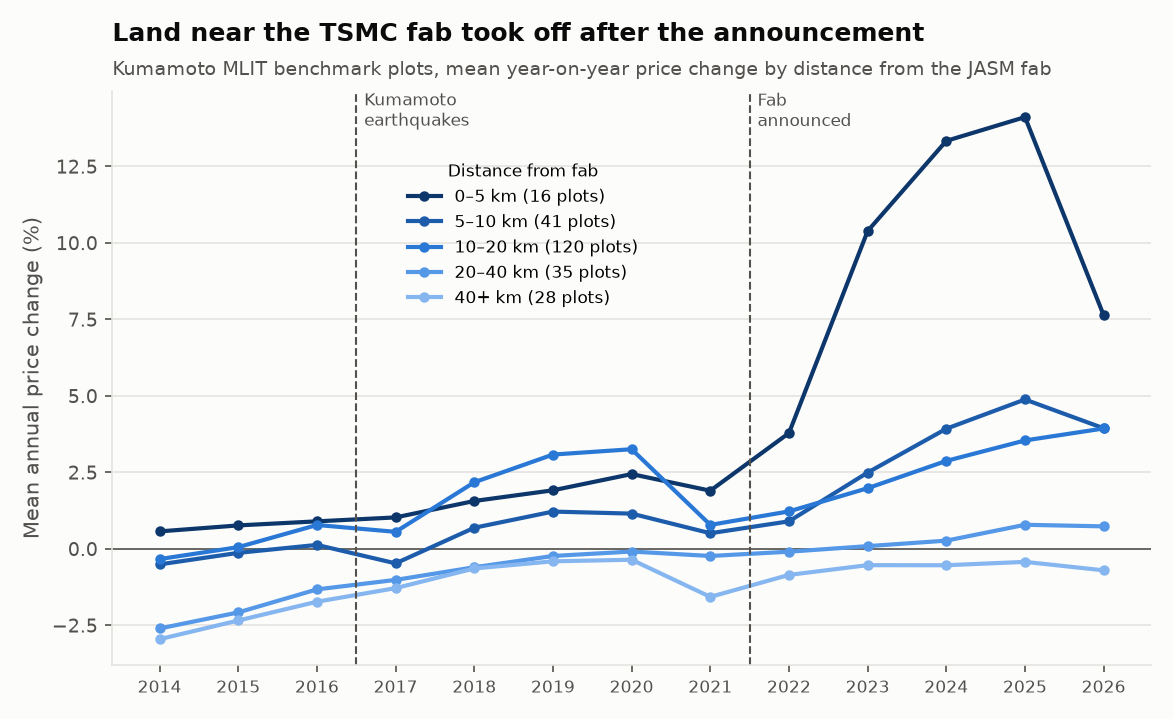

In [2]:
display(Image(filename=fab_impact.BANDS_FIGURE))

## 2. How far does the effect reach?

Prices were rising in many places, so a chart alone cannot show how much of the rise is due to the fab. The estimate below compares each plot with **its own pre-announcement trend** and with **the prefecture-wide market in the same year**. What remains is the extra growth linked to being near the fab. The bars show that extra growth per year since 2022, with 95% confidence ranges.

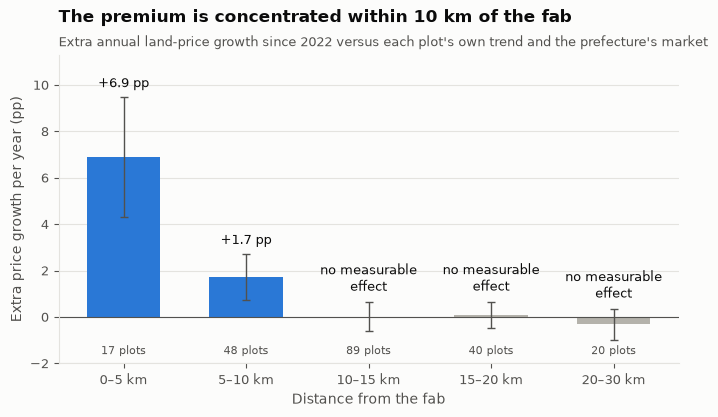

In [3]:
fig, ax = plot_style.figure(8, 4)
significant = rings["p_value"] < 0.05
colors = [plot_style.SERIES if s else "#b4b2ab" for s in significant]
ax.bar(rings["ring"], rings["estimate_pp"], color=colors, width=0.6,
       yerr=[rings["estimate_pp"] - rings["ci_low"], rings["ci_high"] - rings["estimate_pp"]],
       error_kw={"ecolor": plot_style.TEXT_SECONDARY, "elinewidth": 1, "capsize": 3})
ax.axhline(0, color=plot_style.TEXT_SECONDARY, linewidth=0.8)
for x, (est, high, sig, n) in enumerate(zip(rings["estimate_pp"], rings["ci_high"], significant, rings["n_plots"])):
    label = f"{est:+.1f} pp" if sig else "no measurable\neffect"
    ax.text(x, max(high, 0) + 0.3, label, ha="center", va="bottom", fontsize=9, color=plot_style.TEXT)
    ax.text(x, -1.6, f"{n} plots", ha="center", fontsize=8, color=plot_style.TEXT_SECONDARY)
ax.set_ylim(-2, rings["ci_high"].max() + 1.8)
ax.set_ylabel("Extra price growth per year (pp)")
ax.set_xlabel("Distance from the fab")
plot_style.title(ax, "The premium is concentrated within 10 km of the fab",
                 "Extra annual land-price growth since 2022 versus each plot's own trend and the prefecture's market")

In [4]:
main = did["main"]
print(f"Within 10 km overall: {main['estimate_pp']:+.1f} pp per year "
      f"(95% range {main['ci_low']:+.1f} to {main['ci_high']:+.1f}), based on {main['n_near_plots']} plots near the fab "
      f"and {main['n_plots'] - main['n_near_plots']} farther away.")

Within 10 km overall: +3.0 pp per year (95% range +1.9 to +4.2), based on 65 plots near the fab and 206 farther away.


**Is it really the fab?** The check is whether plots near and far from the fab were already moving apart *before* the announcement. If they were, the gap after 2022 could have nothing to do with the fab.

The chart compares near plots (within 10 km) with the rest, year by year, relative to 2021. Outside Kumamoto City (orange), near and far plots tracked each other from 2014 to 2020. The one exception is 2017, the first valuation after the 2016 earthquakes, which hit the towns next to the fab. With Kumamoto City included (blue), near plots lagged slightly in 2017–2020 while the city boomed during post-earthquake rebuilding. Either way, the post-2022 gaps are several times larger than anything before them.

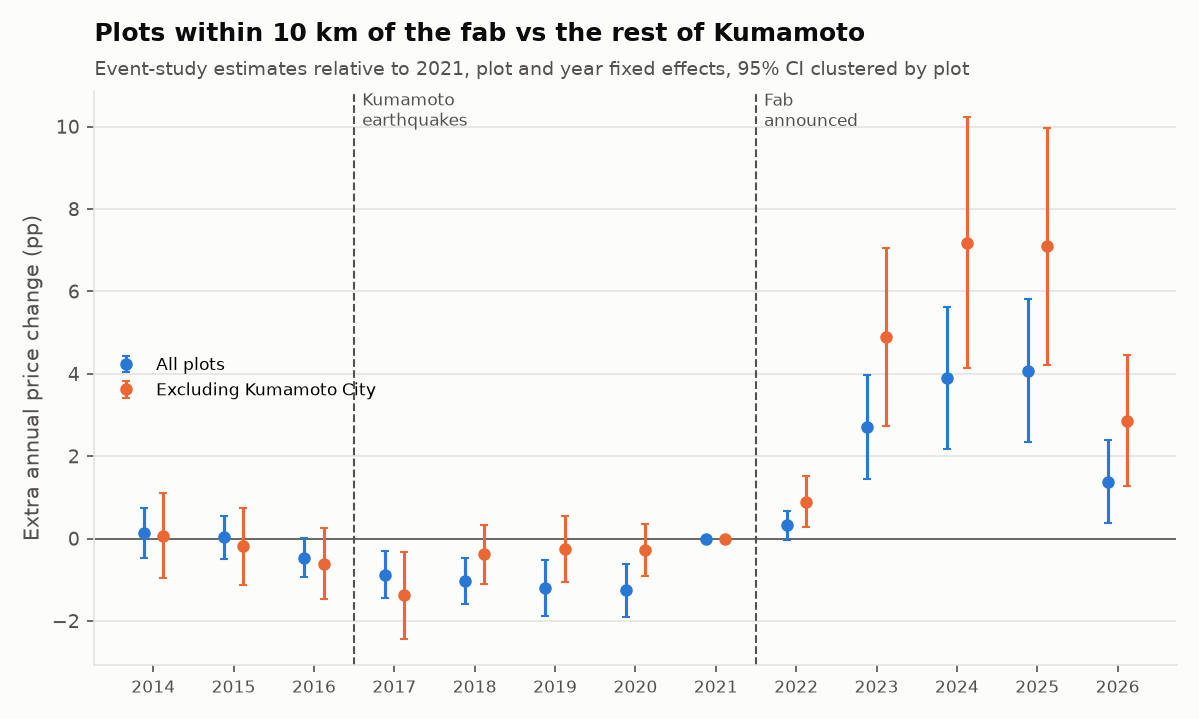

In [5]:
display(Image(filename=fab_impact.EVENT_STUDY_FIGURE))

## 3. Who gained, and by how much

Median price change from the 2021 valuation (the last before the announcement) to 2026, for each municipality with at least three benchmark plots. Bars in blue are towns whose plots are mostly within 10 km of the fab.

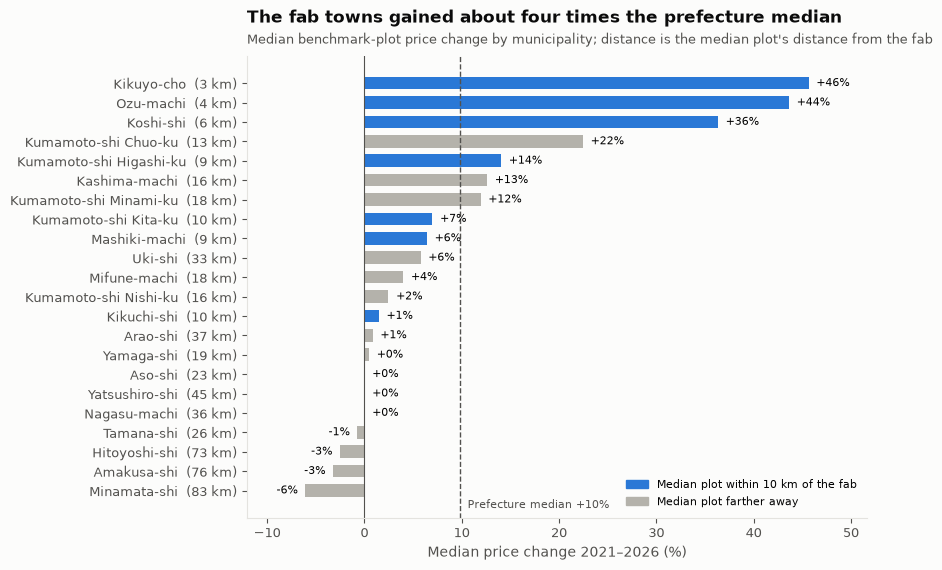

In [6]:
towns = (cum.groupby("municipality")
         .agg(plots=("cum_change", "size"), change=("cum_change", "median"), km=("distance_to_jasm_km", "median"))
         .query("plots >= 3").sort_values("change"))
prefecture = cum["cum_change"].median()

fig, ax = plot_style.figure(8, 6)
colors = [plot_style.SERIES if km <= 10 else "#b4b2ab" for km in towns["km"]]
ax.barh([f"{m}  ({km:.0f} km)" for m, km in zip(towns.index, towns["km"])], towns["change"], color=colors, height=0.65)
ax.axvline(prefecture, color=plot_style.TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.text(prefecture + 0.8, -0.9, f"Prefecture median {prefecture:+.0f}%", fontsize=8, color=plot_style.TEXT_SECONDARY)
for y, v in enumerate(towns["change"]):
    ax.text(v + (0.8 if v >= 0 else -0.8), y, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color=plot_style.TEXT_SECONDARY, linewidth=0.8)
ax.set_xlim(towns["change"].min() - 6, towns["change"].max() + 6)
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=plot_style.SERIES, label="Median plot within 10 km of the fab"),
                   Patch(color="#b4b2ab", label="Median plot farther away")],
          frameon=False, fontsize=8, loc="lower right")
ax.set_xlabel("Median price change 2021–2026 (%)")
plot_style.title(ax, "The fab towns gained about four times the prefecture median",
                 "Median benchmark-plot price change by municipality; distance is the median plot's distance from the fab")

**In yen.** Residential benchmark plots only, so that shops and offices in city centres do not skew the comparison. "Change for a 250 m² lot" scales the typical change per m² to a plot of roughly median size.

In [7]:
res = cum[cum["land_use"] == "residential"].copy()
res["ring"] = pd.cut(res["distance_to_jasm_km"], [0, 5, 10, 20, 40, 200],
                     labels=["0–5 km", "5–10 km", "10–20 km", "20–40 km", "40+ km"])
res["yen_change"] = res["price_last"] - res["price_first"]
yen = res.groupby("ring", observed=True).agg(
    plots=("cum_change", "size"),
    price_2021=("price_first", "median"),
    price_2026=("price_last", "median"),
    change_pct=("cum_change", "median"),
    yen_per_m2=("yen_change", "median"),
)
yen["lot_250"] = yen["yen_per_m2"] * 250
(yen.rename_axis("Distance from fab")
    .style.format({"price_2021": "¥{:,.0f}", "price_2026": "¥{:,.0f}", "change_pct": "{:+.0f}%",
                   "yen_per_m2": lambda v: f"{'+' if v >= 0 else '−'}¥{abs(v):,.0f}",
                   "lot_250": lambda v: f"{'+' if v >= 0 else '−'}¥{abs(v) / 1e6:.1f}M"})
    .relabel_index(["Plots", "Median ¥/m² 2021", "Median ¥/m² 2026", "Median change",
                    "Median change ¥/m²", "Change for a 250 m² lot"], axis=1))

,Plots,Median ¥/m² 2021,Median ¥/m² 2026,Median change,Median change ¥/m²,Change for a 250 m² lot
Distance from fab,,,,,,
0–5 km,10,"¥50,550","¥72,200",+42%,"+¥21,950",+¥5.5M
5–10 km,28,"¥48,000","¥53,750",+13%,"+¥7,000",+¥1.8M
10–20 km,72,"¥65,350","¥71,850",+12%,"+¥6,350",+¥1.6M
20–40 km,22,"¥23,400","¥24,750",+0%,+¥0,+¥0.0M
40+ km,16,"¥24,500","¥23,950",-3%,−¥850,−¥0.2M


Across all land uses, the median plot within 10 km gained about 20% from 2021 to 2026, against about 5% farther away. Plots 10–20 km away (mostly Kumamoto City) also rose by double digits. The analysis in section 2 shows that this growth continued at the city's pre-announcement pace, so it is **not** attributable to the fab.

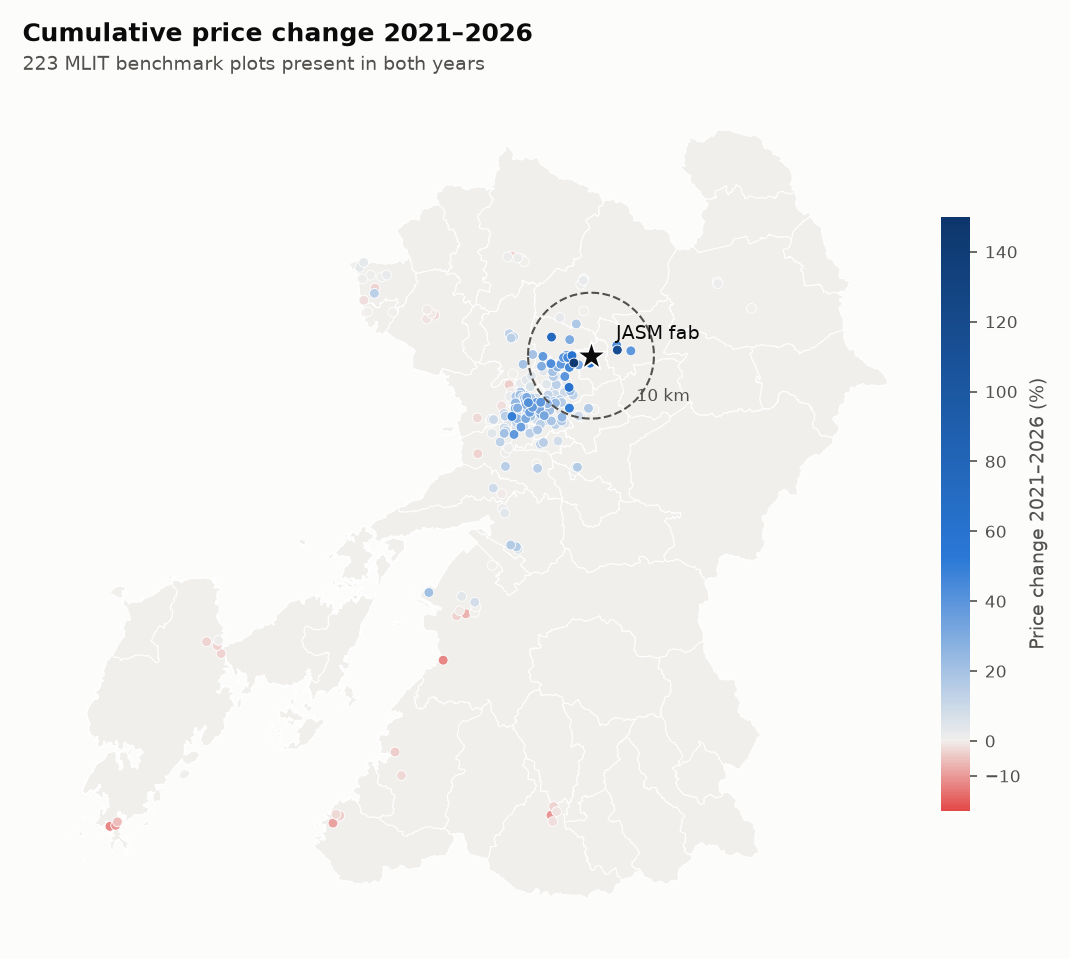

In [8]:
display(Image(filename=fab_impact.MAP_FIGURE))

## 4. The boom is cooling

The 2026 valuation is the first in which growth near the fab slowed. Plots within 5 km still rose faster than anywhere else, but at about half the 2025 pace. The difference from the rest of the prefecture also narrowed (section 2 chart, 2026).

In [9]:
recent = bands[bands["year"] >= 2023].pivot(index="band", columns="year", values="mean_pct_change")
recent = recent.reindex([b[2] for b in fab_impact.BANDS])
recent.rename_axis("Distance from fab").rename_axis("Mean annual change", axis=1).style.format("{:+.1f}%")

Mean annual change,2023,2024,2025,2026
Distance from fab,,,,
0–5 km,+10.4%,+13.3%,+14.1%,+7.6%
5–10 km,+2.5%,+3.9%,+4.9%,+3.9%
10–20 km,+2.0%,+2.9%,+3.5%,+3.9%
20–40 km,+0.1%,+0.3%,+0.8%,+0.7%
40+ km,-0.5%,-0.5%,-0.4%,-0.7%


One year is not a trend. Whether this is a plateau, a pause before the planned second fab, or the start of a correction cannot be read from benchmark appraisals alone (see the plan in section 8).

## 5. Flood exposure in the growth zone

Planners will want to know whether the fastest-appreciating land, and the development it attracts, sits in flood-prone areas. Using MLIT's flood-inundation zones, the plots near the fab are mostly on higher ground; flood exposure is concentrated in Kumamoto City.

In [10]:
latest = s2.sort_values("valuation_year").groupby("plot_id").last()
latest["ring"] = pd.cut(latest["distance_to_jasm_km"], [0, 5, 10, 20, 40, 200],
                        labels=["0–5 km", "5–10 km", "10–20 km", "20–40 km", "40+ km"])
flood = latest.groupby("ring", observed=True).agg(plots=("flood_risk_class", "size"),
                                                  in_flood_zone=("flood_risk_class", lambda s: (s > 0).sum()))
flood["share"] = flood["in_flood_zone"] / flood["plots"]
(flood.rename_axis("Distance from fab")
      .style.format({"share": "{:.0%}"})
      .relabel_index(["Plots", "In a mapped flood zone", "Share"], axis=1))

,Plots,In a mapped flood zone,Share
Distance from fab,,,
0–5 km,17,1,6%
5–10 km,48,6,12%
10–20 km,129,70,54%
20–40 km,43,11,26%
40+ km,34,15,44%


Caveat: the flood layer is MLIT's FY2012 edition, and benchmark plots are a sample of locations, not every new development site. Updating the layer is a quick item in the plan.

## 6. What the forecasting models can and cannot do

The project also trained machine-learning models (Random Forest and XGBoost) to predict each plot's price change. Trained on 2022–2024 and tested on 2025–2026, **neither model beat the simplest rule: "this year's change will equal last year's".** The models learned the 2022–2024 acceleration and missed the 2026 slowdown.

The models do help in a different task: estimating price changes for plots they have not seen, which is useful for filling gaps between benchmark plots.

In [11]:
forecast = comparison[comparison["split"] == "forecast"].set_index("model")
unseen = comparison[comparison["split"] == "unseen_plots"].set_index("model")
rows = ["Persistence (last year's change)", "Random Forest", "XGBoost"]
table = pd.DataFrame({
    "Forecast 2025–26: average miss (pp)": forecast.loc[rows, "mae"],
    "Forecast 2025–26: R²": forecast.loc[rows, "r2"],
    "Unseen plots: average miss (pp)": unseen.loc[rows, "mae"],
    "Unseen plots: R²": unseen.loc[rows, "r2"],
}).rename(index={"Persistence (last year's change)": "Rule: same as last year"})
table.rename_axis("Method").style.format("{:.2f}")

,Forecast 2025–26: average miss (pp),Forecast 2025–26: R²,Unseen plots: average miss (pp),Unseen plots: R²
Method,,,,
Rule: same as last year,0.98,0.72,0.96,0.69
Random Forest,1.22,0.64,0.88,0.79
XGBoost,1.16,0.69,0.87,0.78


**Practical meaning:** do not use this project's models to forecast next year's land prices. Last year's change is as good a guide as anything here, and it misses turning points. Better forecasts need leading indicators such as transaction volumes, building permits and population inflows, not a more complex model on the same data.

## 7. What this means for decisions

**Prefecture and municipal planners**
- The fab's price pressure is concentrated in Kikuyo, Ozu and Koshi and fades out by about 10 km. Housing-affordability and infrastructure measures aimed at the fab's effects can be targeted there rather than prefecture-wide.
- Kumamoto City's rise is its own trend, not a fab spillover. Policies there should not be justified on the fab's account.
- The appreciation zone is largely outside mapped flood areas, which is reassuring for development that follows it. This should be re-checked with current flood maps.

**Landowners and developers**
- The premium is very local. Being 5 km or 15 km from the fab makes a large difference, and the 10–20 km band showed no fab premium at all.
- Growth near the fab halved in 2026. Past momentum is not a reliable guide to the next few years.

**Investors**
- The analysis measures what has happened; it does not provide a price forecast, and nothing here is investment advice. The evidence is consistent with a one-off repricing of land near the fab that is now slowing, rather than a steady trend.

## How much to trust these numbers

- **Data accuracy:** the price changes computed here match MLIT's own published change rates exactly for all 1,216 plot-years where MLIT publishes one.
- **Benchmark prices are expert appraisals, not sale prices.** Appraisals react to the market with a lag and smooth it, so real transaction prices near the fab may have moved more, and earlier.
- **Small numbers near the fab:** only 13–17 benchmark plots lie within 5 km, so the 5 km figures have wide ranges (about 4 to 9 points a year).
- **"The fab" means the fab and everything that followed it:** suppliers, housing demand, road projects and expectations about the second fab are all part of the measured effect.

## 8. Making the project more valuable: plan

**Where the value is today:** a validated, reproducible measurement of how much and how far the fab moved land prices, rerunnable in a few minutes each year.

**Where it falls short:** too few plots near the fab for precise local figures, appraisal values that lag the market, no view of who is affected (renters, households), and no forecasting value.

| # | Work | What it adds for stakeholders | Effort | Needs |
|---|---|---|---|---|
| 1 | **Add the prefectural land price survey** (都道府県地価調査, NLNI dataset L02), valued every July 1 | A second, independent set of benchmark plots, so more plots near the fab and tighter estimates, plus a mid-year reading six months before the next MLIT release | 1–2 days: same source and format as the current data | Nothing new |
| 2 | **Annual refresh and monitor** | One command after each March (L01) and September (L02) release updates every figure and the dashboard, with a short "what changed" summary per distance ring | 1 day | Nothing new |
| 3 | **Update the flood layer** to MLIT's current flood-inundation maps, and add landslide and liquefaction exposure for the growth zone | A current hazard check on where the fab is pulling development | 0.5–1 day | Nothing new |
| 4 | **Add actual transaction prices** (MLIT Real Estate Information Library API) | Real sale prices and deal volumes, quarterly. Shows whether the market is running ahead of appraisals and gives an earlier read on the 2026 slowdown | 2–3 days | Free API key |
| 5 | **Add housing and population data** (e-Stat: rents, household inflows by municipality) | An affordability and displacement view: who is being priced out, and where | 3–5 days | Free app ID |
| 6 | **Separate the first fab from the second** (announced in February 2024) | Whether the 2024–2026 valuations already price in the second fab, and what remains to come | Needs items 1 and 4 first | — |

**Recommended next step:** items 1–3. They need no new accounts, take under a week together, and directly strengthen the figures stakeholders will use: more plots near the fab, a twice-yearly reading and a current hazard check.

**What not to invest in:** more complex price-forecasting models on benchmark data alone. The comparison in section 6 shows the data does not support it. Forecasting becomes worthwhile only after transaction and population data (items 4–5) supply leading indicators.